In [1]:
import re
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from IPython.display import display
from PIL import Image, ImageFile, ImageOps

ROOT = Path.cwd().parent
DATA = ROOT / "all_datasets"
RESULTS = ROOT / "results" / "lab06"
RESULTS.mkdir(parents=True, exist_ok=True)

# Accept mildly truncated photographs and record any OCR-engine failure per image.
ImageFile.LOAD_TRUNCATED_IMAGES = True
windows_default = Path(r"C:\Program Files\Tesseract-OCR\tesseract.exe")
tesseract = shutil.which("tesseract")
if tesseract is None and windows_default.is_file():
    tesseract = str(windows_default)

OCR_MODE = "live" if tesseract else "cached"
if OCR_MODE == "live":
    pytesseract.pytesseract.tesseract_cmd = tesseract
    print("OCR mode: live | Tesseract", pytesseract.get_tesseract_version(), "at", tesseract)
else:
    print("OCR mode: cached | install Tesseract and restart the kernel for a live rerun")

OCR mode: live | Tesseract 5.4.0.20240606 at C:\Program Files\Tesseract-OCR\tesseract.exe


In [5]:
%pip install pytesseract pillow

Note: you may need to restart the kernel to use updated packages.


Labelled images: 89 | unique labels: 61


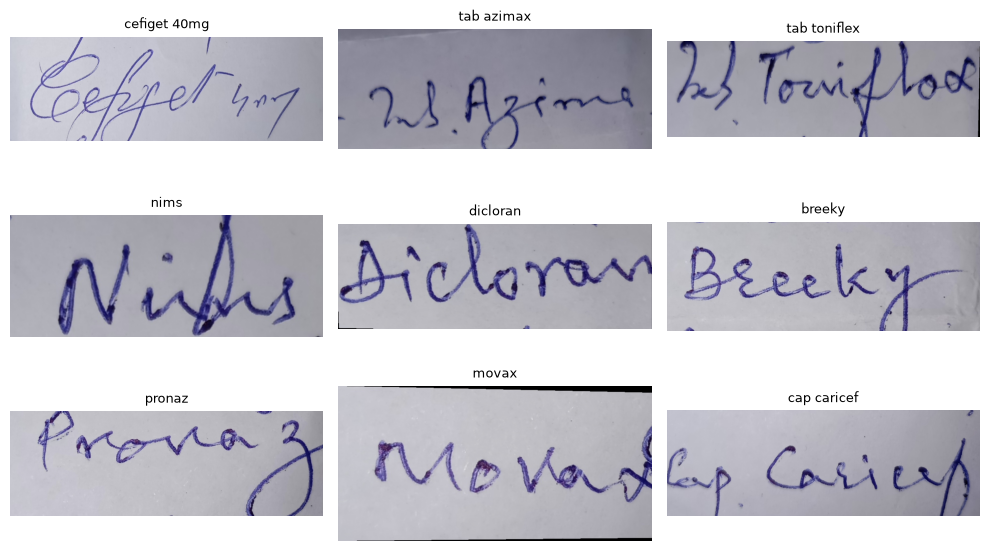

In [ ]:
#Ques 1: Validate the archive

# where the images live after unzipping
IMAGES = DATA / "lab06-ocr-handwritten-prescription"
# only unzip if we haven't already, so rerunning the cell doesn't redo it
if not IMAGES.exists():
    zipfile.ZipFile(DATA / "lab06-ocr-handwritten-prescription.zip").extractall(IMAGES)

labels = pd.read_csv(IMAGES / "doctor_handwriting_labels.csv")

# build the full path to each image so we can open it later
labels["path"] = [IMAGES / "img" / "img" / name for name in labels.filename]
assert len(labels) == 89 and labels.filename.is_unique and all(p.exists() for p in labels.path)
print("Labelled images:", len(labels), "| unique labels:", labels.label.nunique())


def load_image(path):
    """Load the pixels now so the source file can close safely."""
    with Image.open(path) as image:
        return image.copy()


fig, axes = plt.subplots(3, 3, figsize=(10, 6))
for ax, row in zip(axes.flat, labels.head(9).itertuples()):
    ax.imshow(load_image(row.path))
    ax.set_title(row.label, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "sample_grid.png", dpi=150)

In [ ]:
#Ques 2: Baseline OCR
OCR_CONFIG = "--oem 1 --psm 7"


def normalise(text):
    # lowercase it and strip everything except letters and digits, so spaces/punctuation don't count as mistakes
    return re.sub(r"[^a-z0-9]", "", str(text).lower())


def run_ocr(paths, pipeline):
    """Return one auditable row per image, including engine status."""
    # cached mode: no Tesseract installed, so reuse the predictions that came with the course package
    if OCR_MODE == "cached":
        cache_path = RESULTS / "predictions.csv"
        if not cache_path.is_file():
            raise RuntimeError("Tesseract is unavailable and predictions.csv is missing; install Tesseract and rerun.")
        cached = pd.read_csv(cache_path).fillna("")
        cached = cached[cached.pipeline == pipeline].copy()
        assert len(cached) == len(labels) and set(cached.filename) == set(labels.filename)
        cached["ocr_status"] = "cached"
        cached["ocr_detail"] = "validated prediction supplied with the course package"
        return cached

    # live mode: actually run Tesseract on each image
    rows = []
    for row, path in zip(labels.itertuples(), paths):
        try:
            prediction = pytesseract.image_to_string(load_image(path), config=OCR_CONFIG).strip()
            status, detail = "ok", ""
        except pytesseract.TesseractError as error:
            # if the engine crashes on one image, don't stop: record it as a blank and keep going
            prediction = ""
            status, detail = "engine_error", error.message[:160]
        rows.append({"filename": row.filename, "pipeline": pipeline, "truth": row.label, "prediction": prediction,
                     "truth_norm": normalise(row.label), "prediction_norm": normalise(prediction),
                     "ocr_status": status, "ocr_detail": detail})
    return pd.DataFrame(rows)

# run the baseline on the raw, untouched images
baseline = run_ocr(labels.path, "baseline")
# peek at the first 8 results
display(baseline[["truth", "prediction", "prediction_norm", "ocr_status"]].head(8))
# how many images made the engine itself fail (different from just reading it wrong)
print("OCR engine errors:", int((baseline.ocr_status == "engine_error").sum()))

,truth,prediction,prediction_norm,ocr_status
0,cefiget 40mg,,,ok
1,tab azimax,Age,age,ok
2,tab toniflex,b5 Towid host,b5towidhost,ok
3,nims,Nidu,nidu,ok
4,dicloran,divlerer,divlerer,ok
5,breeky,,,ok
6,pronaz,oa,oa,ok
7,movax,Ae Vag,aevag,ok


OCR engine errors: 0


In [ ]:
#Ques 3: Recognition quality
def levenshtein(a, b):
    """Minimum number of single-character edits that turn a into b."""
    # previous[j] = edits needed to turn the first i-1 letters of a into the first j letters of b
    previous = list(range(len(b) + 1))
    for i, char_a in enumerate(a, start=1):
        current = [i] # turning i letters of a into nothing takes i deletions
        for j, char_b in enumerate(b, start=1):
            current.append(min(current[j - 1] + 1, #insert a letter
                               previous[j] + 1, #delete a letter
                                 previous[j - 1] + (char_a != char_b))) #swap a letter(free if they already match)
        previous = current
    return previous[-1] # last cell = edits for the full strings


def add_distances(frame):
    frame = frame.copy() # don't mess with the original table
    # exact match: prediction is identical to the label after cleaning
    frame["exact"] = frame.truth_norm == frame.prediction_norm
    # raw number of edits for each image
    frame["edits"] = [levenshtein(t, p) for t, p in zip(frame.truth_norm, frame.prediction_norm)]
    longest = np.maximum(frame.truth_norm.str.len(), frame.prediction_norm.str.len()).clip(lower=1)
    frame["normalised_edit_distance"] = frame.edits / longest
    return frame


def summarise(frame):
    return {"pipeline": frame.pipeline.iat[0],
            "exact_match_accuracy": frame.exact.mean(),
            "mean_normalised_edit_distance": frame.normalised_edit_distance.mean(),
            "character_error_rate": frame.edits.sum() / frame.truth_norm.str.len().sum(),
            "blank_predictions": int((frame.prediction_norm == "").sum())}


baseline = add_distances(baseline)
display(pd.DataFrame([summarise(baseline)]).round(4))

,pipeline,exact_match_accuracy,mean_normalised_edit_distance,character_error_rate,blank_predictions
0,baseline,0.0,0.8687,0.8831,42


In [6]:
#Ques 4: Preprocessing Pipeline
def preprocess(path, output):
    image = ImageOps.exif_transpose(load_image(path)).convert("L")
    image = ImageOps.expand(image, border=20, fill=255)
    if image.width > 1200:
        image = image.resize((1200, round(image.height * 1200 / image.width)), Image.Resampling.LANCZOS)
    image = image.resize((round(image.width * 1.5), round(image.height * 1.5)), Image.Resampling.BICUBIC)
    image.save(output)
    return output


(RESULTS / "preprocessed").mkdir(exist_ok=True)
preprocessed_paths = [preprocess(path, RESULTS / "preprocessed" / f"{i:03d}.png") for i, path in enumerate(labels.path)]
example = Image.open(preprocessed_paths[0])
print("Prepared images:", len(preprocessed_paths), "| example size:", example.size, "mode:", example.mode)

Prepared images: 89 | example size: (1800, 638) mode: L


In [ ]:
#Ques 5: Compare the two pipelines
# run OCR on the cleaned-up images, using the exact same config as before, then score them
preprocessed = add_distances(run_ocr(preprocessed_paths, "grayscale_border_resize"))
pd.concat([baseline, preprocessed]).to_csv(RESULTS / "predictions.csv", index=False)
# one row of overall scores per pipeline, side by side, then save that too
metrics = pd.DataFrame([summarise(baseline), summarise(preprocessed)]).set_index("pipeline")
metrics.to_csv(RESULTS / "metrics.csv")
display(metrics.round(4))

# how much did preprocessing change each score? (negative = fewer errors/blanks, which is good)
display((metrics.loc["grayscale_border_resize"] - metrics.loc["baseline"]).rename("change").round(3).to_frame())

,exact_match_accuracy,mean_normalised_edit_distance,character_error_rate,blank_predictions
pipeline,,,,
baseline,0.0000,0.8687,0.8831,42
grayscale_border_resize,0.0112,0.7851,0.8065,15


,change
exact_match_accuracy,0.011
mean_normalised_edit_distance,-0.084
character_error_rate,-0.077
blank_predictions,-27.000


,truth,prediction,failure_type
60,azitma,,no text detected
61,tonoflox,,no text detected
0,cefiget 40mg,,no text detected
5,breeky,,no text detected
13,tab nims 100mg,,no text detected
17,cap caricef 40mg,,no text detected
19,tab novidat,| i» welll,character confusion
20,tab distalgesic,wr,character confusion


Saved: ['error_analysis.csv', 'metrics.csv', 'ocr_failures.png', 'predictions.csv', 'sample_grid.png']


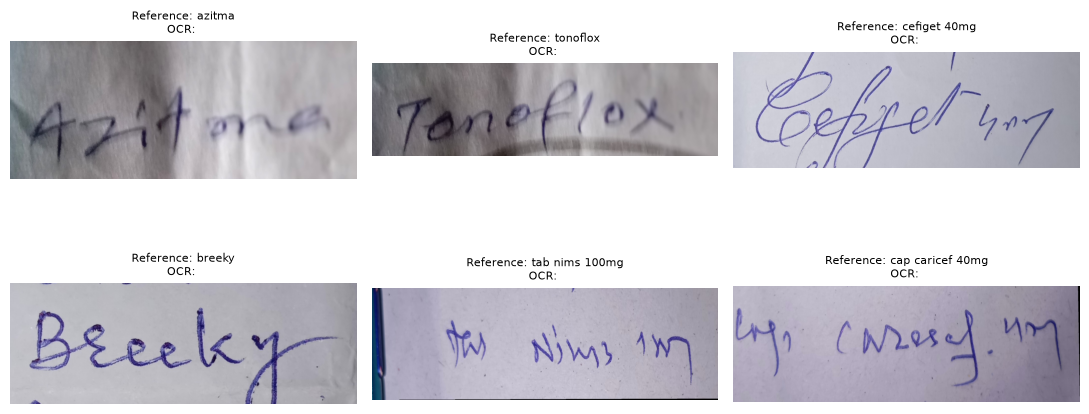

In [ ]:
#Ques 6: Failure analysis
# find the worst misses: drop the images we got exactly right, then sort by error
# (worst first, filename as a tiebreaker so the order is always the same) and keep the top 8
errors = preprocessed[~preprocessed.exact].sort_values(["normalised_edit_distance", "filename"], ascending=[False, True]).head(8)

# label each failure with what kind of failure it was:
#   engine crashed -> "engine error", nothing read -> "no text detected", otherwise it read something wrong
errors = errors.assign(failure_type=np.select(
    [errors.ocr_status == "engine_error", errors.prediction_norm == ""],
    ["engine error", "no text detected"],
    default="character confusion",
))


errors[["filename", "truth", "prediction", "failure_type"]].to_csv(RESULTS / "error_analysis.csv", index=False)
display(errors[["truth", "prediction", "failure_type"]])

fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, row in zip(axes.flat, errors.head(6).itertuples()):
    ax.imshow(load_image(IMAGES / "img" / "img" / row.filename))
    ax.set_title(f"Reference: {row.truth}\nOCR: {row.prediction[:28]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "ocr_failures.png", dpi=150)
print("Saved:", sorted(p.name for p in RESULTS.iterdir() if p.is_file()))